# THỰC HÀNH 01 – PHÂN TÍCH KHÁM PHÁ DỮ LIỆU (EDA)

Notebook này gồm các **Bài tập thực hành 1** của 3 phần:

| Phần | Nội dung | Dữ liệu |
|---|---|---|
| 1 | Thống kê mô tả (mục 1.1.3) | Red Wine Quality |
| 2 | Xử lý và trực quan hóa dữ liệu (mục 1.2.2) | Red Wine Quality |
| 3 | Công cụ EDA tự động – SweetViz (mục 1.3.3) | Marketing Campaign |

**Dữ liệu cần chuẩn bị** (đặt trong thư mục `./data`):
- `winequality-red.csv` – https://www.kaggle.com/datasets/uciml/red-wine-quality-cortez-et-al-2009
- `marketing_campaign.csv` – https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis

In [1]:
# Cài đặt thư viện (bỏ comment nếu cần)
# !pip install numpy pandas scipy matplotlib seaborn sweetviz

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

import os, glob

def find_file(*candidates):
    """Tìm file dữ liệu trong thư mục hiện tại, ./data, ./Data hoặc /kaggle/input."""
    folders = [".", "data", "Data", "/kaggle/input"]
    for name in candidates:
        for f in folders:
            p = os.path.join(f, name)
            if os.path.exists(p):
                return p
        hits = glob.glob(os.path.join("/kaggle/input", "**", name), recursive=True)
        if hits:
            return hits[0]
    raise FileNotFoundError(f"Không tìm thấy {candidates}. Hãy tải dữ liệu từ Kaggle và đặt vào thư mục ./data")


# PHẦN 1. THỐNG KÊ MÔ TẢ – RED WINE QUALITY
## 1.1 Nạp dữ liệu và quan sát tổng quan

In [3]:
wine = pd.read_csv(find_file("winequality-red.csv", "winequality_red.csv"))
# Nếu file dùng dấu ';' làm ngăn cách thì tự đọc lại
if wine.shape[1] == 1:
    wine = pd.read_csv(find_file("winequality-red.csv", "winequality_red.csv"), sep=";")

print("Kích thước (dòng, cột):", wine.shape)
wine.head()

Kích thước (dòng, cột): (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [4]:
wine.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [5]:
print("Kiểu dữ liệu:")
print(wine.dtypes)
print("\nGiá trị thiếu mỗi cột:")
print(wine.isnull().sum())
print("\nSố dòng trùng lặp:", wine.duplicated().sum())

Kiểu dữ liệu:
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

Giá trị thiếu mỗi cột:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Số dòng trùng lặp: 240


## 1.2 Làm sạch dữ liệu (loại bỏ trùng lặp)

In [6]:
wine_clean = wine.drop_duplicates().reset_index(drop=True)
print("Trước:", wine.shape, "| Sau khi bỏ trùng:", wine_clean.shape)

Trước: (1599, 12) | Sau khi bỏ trùng: (1359, 12)


## 1.3 Các thước đo thống kê mô tả
Tính **mean, median, mode, variance, standard deviation, range, percentile, quartile, IQR** bằng `numpy` và `scipy.stats` (như bài mẫu), trước hết trên biến `alcohol`.

In [7]:
col = "alcohol"
x = wine_clean[col]

data_mean = np.mean(x)
data_median = np.median(x)
data_mode = stats.mode(x, keepdims=False)
data_var = np.var(x)
data_sd = np.std(x)
data_max, data_min = np.max(x), np.min(x)
data_range = data_max - data_min
data_p60 = np.percentile(x, 60)
q1, q2, q3 = np.quantile(x, [0.25, 0.5, 0.75])
data_iqr = stats.iqr(x)

print(f"Biến: {col}")
print(f"Mean              : {data_mean:.4f}")
print(f"Median            : {data_median:.4f}")
print(f"Mode              : {data_mode.mode} (xuất hiện {data_mode.count} lần)")
print(f"Variance          : {data_var:.4f}")
print(f"Std deviation     : {data_sd:.4f}")
print(f"Min / Max / Range : {data_min} / {data_max} / {data_range:.2f}")
print(f"Percentile 60     : {data_p60:.4f}")
print(f"Q1 / Q2 / Q3      : {q1:.4f} / {q2:.4f} / {q3:.4f}")
print(f"IQR               : {data_iqr:.4f}")

Biến: alcohol
Mean              : 10.4323
Median            : 10.2000
Mode              : 9.5 (xuất hiện 111 lần)
Variance          : 1.1700
Std deviation     : 1.0817
Min / Max / Range : 8.4 / 14.9 / 6.50
Percentile 60     : 10.5000
Q1 / Q2 / Q3      : 9.5000 / 10.2000 / 11.1000
IQR               : 1.6000


### Mở rộng cho tất cả các biến số

In [8]:
num_cols = wine_clean.select_dtypes(include=np.number).columns

summary = pd.DataFrame({
    "mean": wine_clean[num_cols].mean(),
    "median": wine_clean[num_cols].median(),
    "mode": wine_clean[num_cols].mode().iloc[0],
    "variance": wine_clean[num_cols].var(),
    "std": wine_clean[num_cols].std(),
    "min": wine_clean[num_cols].min(),
    "max": wine_clean[num_cols].max(),
    "range": wine_clean[num_cols].max() - wine_clean[num_cols].min(),
    "Q1": wine_clean[num_cols].quantile(0.25),
    "Q3": wine_clean[num_cols].quantile(0.75),
    "IQR": wine_clean[num_cols].apply(stats.iqr),
    "skewness": wine_clean[num_cols].skew(),
    "kurtosis": wine_clean[num_cols].kurt(),
})
summary.round(3)

,mean,median,mode,variance,std,min,max,range,Q1,Q3,IQR,skewness,kurtosis
fixed acidity,8.311,7.900,7.200,3.017,1.737,4.600,15.900,11.300,7.100,9.200,2.100,0.941,1.050
volatile acidity,0.529,0.520,0.500,0.034,0.183,0.120,1.580,1.460,0.390,0.640,0.250,0.729,1.249
citric acid,0.272,0.260,0.000,0.038,0.196,0.000,1.000,1.000,0.090,0.430,0.340,0.313,-0.789
residual sugar,2.523,2.200,2.000,1.829,1.352,0.900,15.500,14.600,1.900,2.600,0.700,4.548,29.365
chlorides,0.088,0.079,0.080,0.002,0.049,0.012,0.611,0.599,0.070,0.091,0.021,5.502,38.625
free sulfur dioxide,15.893,14.000,6.000,109.145,10.447,1.000,72.000,71.000,7.000,21.000,14.000,1.227,1.893
total sulfur dioxide,46.826,38.000,28.000,1116.158,33.409,6.000,289.000,283.000,22.000,63.000,41.000,1.540,4.042
density,0.997,0.997,0.997,0.000,0.002,0.990,1.004,0.014,0.996,0.998,0.002,0.045,0.831
pH,3.310,3.310,3.300,0.024,0.155,2.740,4.010,1.270,3.210,3.400,0.190,0.232,0.880
sulphates,0.659,0.620,0.540,0.029,0.171,0.330,2.000,1.670,0.550,0.730,0.180,2.407,11.102


In [9]:
# Tóm tắt nhanh bằng describe()
wine_clean.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1359.0,8.310596,1.736990,4.60000,7.1000,7.9000,9.20000,15.90000
volatile acidity,1359.0,0.529478,0.183031,0.12000,0.3900,0.5200,0.64000,1.58000
citric acid,1359.0,0.272333,0.195537,0.00000,0.0900,0.2600,0.43000,1.00000
residual sugar,1359.0,2.523400,1.352314,0.90000,1.9000,2.2000,2.60000,15.50000
chlorides,1359.0,0.088124,0.049377,0.01200,0.0700,0.0790,0.09100,0.61100
free sulfur dioxide,1359.0,15.893304,10.447270,1.00000,7.0000,14.0000,21.00000,72.00000
total sulfur dioxide,1359.0,46.825975,33.408946,6.00000,22.0000,38.0000,63.00000,289.00000
density,1359.0,0.996709,0.001869,0.99007,0.9956,0.9967,0.99782,1.00369
pH,1359.0,3.309787,0.155036,2.74000,3.2100,3.3100,3.40000,4.01000
sulphates,1359.0,0.658705,0.170667,0.33000,0.5500,0.6200,0.73000,2.00000


## 1.4 Phân bố và độ lệch
Quy ước: `|skewness| < 0.5` ≈ đối xứng; `0.5–1` lệch vừa; `> 1` lệch mạnh. Skew > 0 là **lệch phải**, < 0 là **lệch trái**.

In [10]:
def skew_label(s):
    if abs(s) < 0.5: return "xấp xỉ đối xứng"
    side = "phải" if s > 0 else "trái"
    return f"lệch {side} " + ("vừa" if abs(s) < 1 else "mạnh")

skew_tbl = summary[["mean", "median", "skewness"]].copy()
skew_tbl["nhận xét"] = skew_tbl["skewness"].apply(skew_label)
skew_tbl.round(3)

,mean,median,skewness,nhận xét
fixed acidity,8.311,7.900,0.941,lệch phải vừa
volatile acidity,0.529,0.520,0.729,lệch phải vừa
citric acid,0.272,0.260,0.313,xấp xỉ đối xứng
residual sugar,2.523,2.200,4.548,lệch phải mạnh
chlorides,0.088,0.079,5.502,lệch phải mạnh
free sulfur dioxide,15.893,14.000,1.227,lệch phải mạnh
total sulfur dioxide,46.826,38.000,1.540,lệch phải mạnh
density,0.997,0.997,0.045,xấp xỉ đối xứng
pH,3.310,3.310,0.232,xấp xỉ đối xứng
sulphates,0.659,0.620,2.407,lệch phải mạnh


## 1.5 Phát hiện giá trị ngoại lai (outliers) bằng quy tắc IQR
Ngoại lai: giá trị < Q1 − 1.5·IQR hoặc > Q3 + 1.5·IQR.

In [11]:
rows = []
for c in num_cols:
    q1, q3 = wine_clean[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((wine_clean[c] < lo) | (wine_clean[c] > hi)).sum()
    rows.append([c, lo, hi, n_out, n_out / len(wine_clean) * 100])

outlier_tbl = pd.DataFrame(rows, columns=["biến", "ngưỡng dưới", "ngưỡng trên", "số ngoại lai", "% ngoại lai"])
outlier_tbl.sort_values("số ngoại lai", ascending=False).round(2)

,biến,ngưỡng dưới,ngưỡng trên,số ngoại lai,% ngoại lai
3,residual sugar,0.85,3.65,126,9.27
4,chlorides,0.04,0.12,87,6.40
9,sulphates,0.28,1.00,55,4.05
6,total sulfur dioxide,-39.50,124.50,45,3.31
0,fixed acidity,3.95,12.35,41,3.02
7,density,0.99,1.00,35,2.58
8,pH,2.92,3.68,28,2.06
11,quality,3.50,7.50,27,1.99
5,free sulfur dioxide,-14.00,42.00,26,1.91
1,volatile acidity,0.02,1.02,19,1.40


## 1.6 Thống kê theo nhóm chất lượng (`quality`)

In [12]:
print("Phân bố nhãn quality:")
print(wine_clean["quality"].value_counts().sort_index())
print()
wine_clean.groupby("quality")[["alcohol", "volatile acidity", "sulphates", "citric acid", "pH"]].agg(["mean", "median", "std"]).round(3)

Phân bố nhãn quality:
quality
3     10
4     53
5    577
6    535
7    167
8     17
Name: count, dtype: int64



alcohol                volatile acidity               sulphates  \
           mean  median    std             mean median    std      mean   
quality                                                                   
3         9.955   9.925  0.818            0.885  0.845  0.331     0.570   
4        10.265  10.000  0.935            0.694  0.670  0.220     0.596   
5         9.889   9.600  0.750            0.579  0.580  0.170     0.624   
6        10.659  10.500  1.055            0.496  0.490  0.163     0.675   
7        11.491  11.600  0.971            0.404  0.370  0.141     0.743   
8        12.159  12.500  1.230            0.428  0.380  0.148     0.775   

                      citric acid                   pH                
        median    std        mean median    std   mean median    std  
quality                                                               
3        0.545  0.122       0.171  0.035  0.251  3.398   3.39  0.144  
4        0.560  0.239       0.174  0.090  0.201  3.382   3.37  0.181  
5        0.580  0.176       0.245  0.230  0.181  3.301   3.30  0.150  
6        0.640  0.155       0.279  0.270  0.196  3.318   3.32  0.155  
7        0.740  0.136       0.372  0.400  0.193  3.290   3.28  0.149  
8        0.740  0.115       0.383  0.390  0.203  3.274   3.23  0.205


# PHẦN 2. TRỰC QUAN HÓA DỮ LIỆU – RED WINE QUALITY
## 2.1 Histogram – phân bố từng biến số

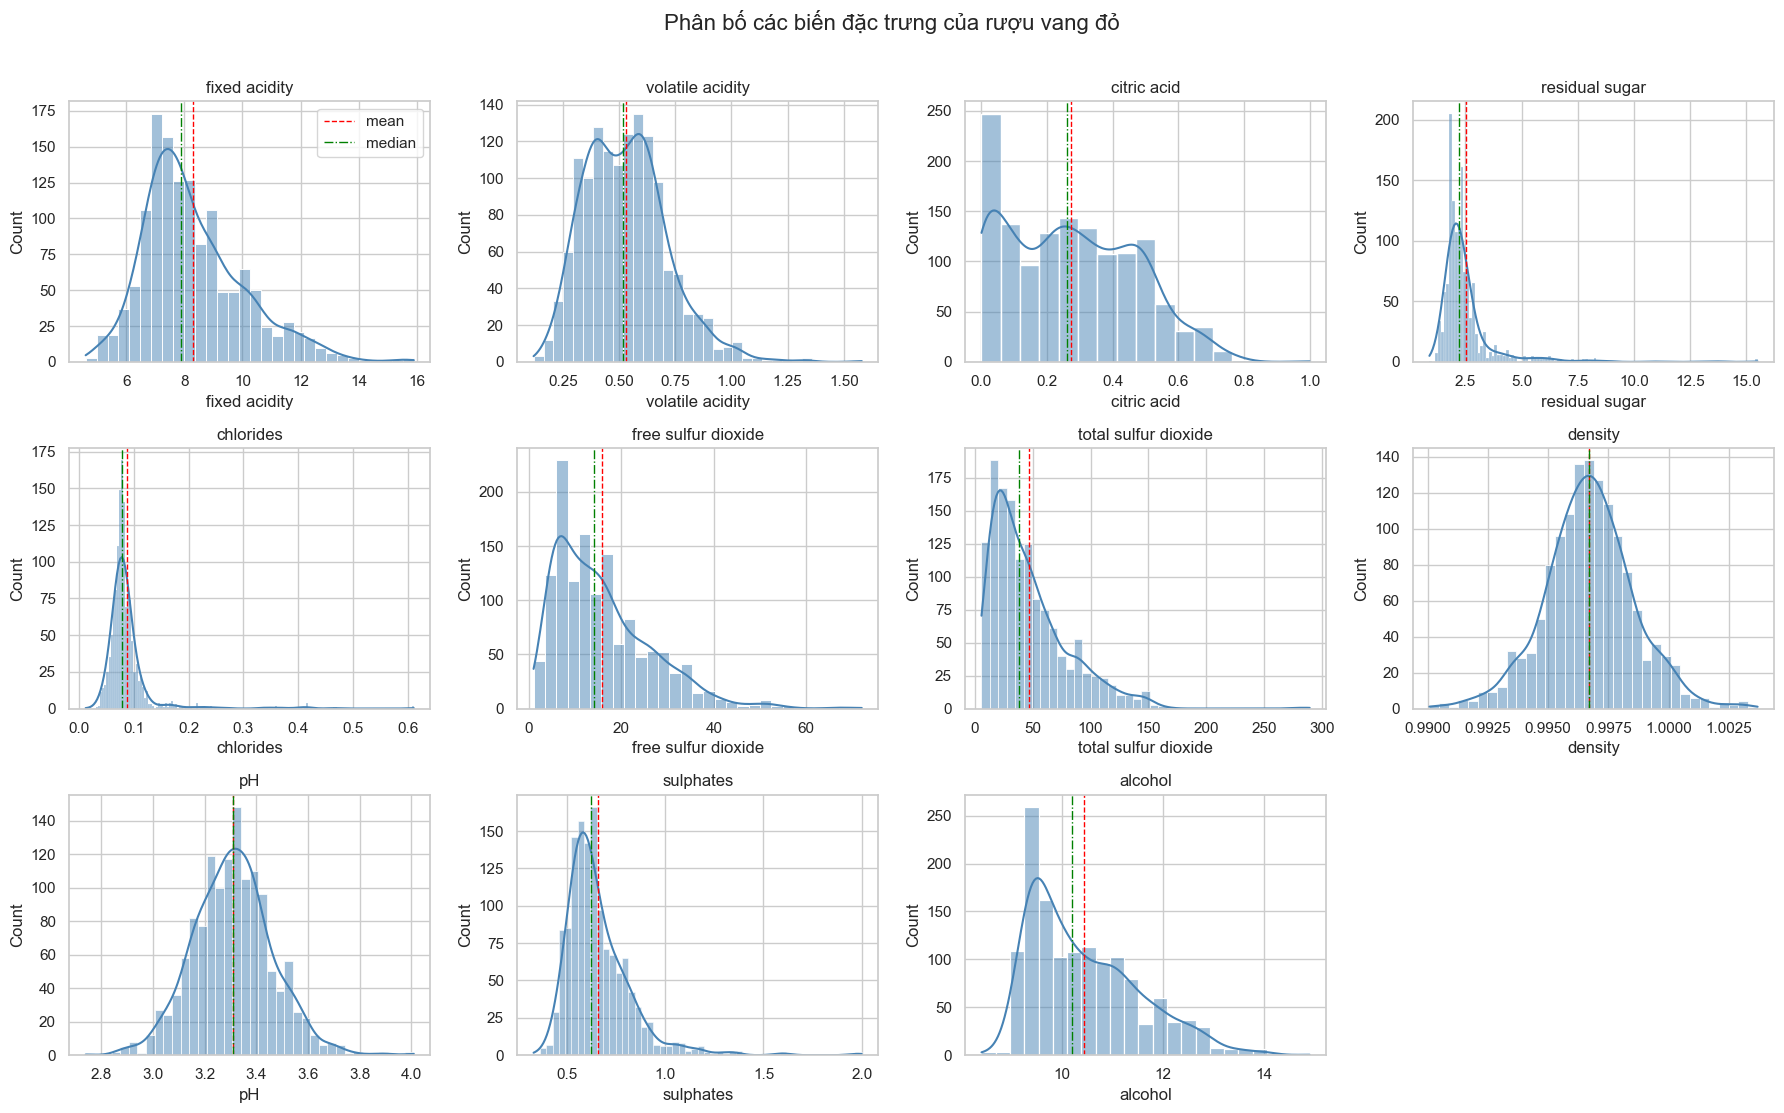

In [13]:
feature_cols = [c for c in num_cols if c != "quality"]

fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, c in zip(axes.ravel(), feature_cols):
    sns.histplot(wine_clean[c], kde=True, ax=ax, color="steelblue")
    ax.axvline(wine_clean[c].mean(), color="red", ls="--", lw=1, label="mean")
    ax.axvline(wine_clean[c].median(), color="green", ls="-.", lw=1, label="median")
    ax.set_title(c)
axes.ravel()[0].legend()
for ax in axes.ravel()[len(feature_cols):]:
    ax.axis("off")
plt.suptitle("Phân bố các biến đặc trưng của rượu vang đỏ", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

## 2.2 Biểu đồ cột / tròn – biến phân loại `quality`

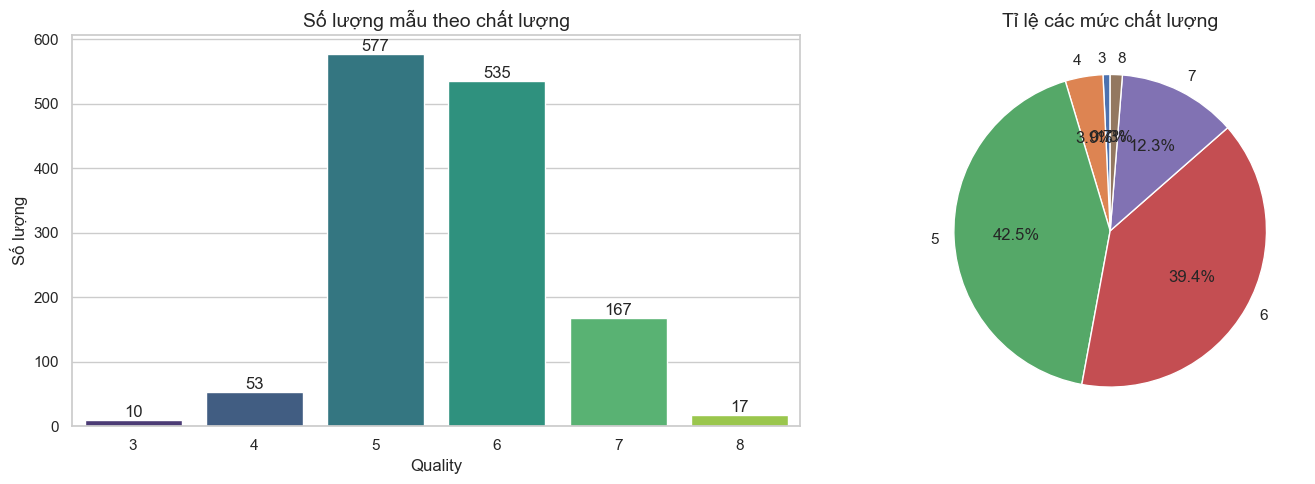

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

order = sorted(wine_clean["quality"].unique())
sns.countplot(data=wine_clean, x="quality", order=order, ax=axes[0], palette="viridis")
for p in axes[0].patches:
    axes[0].annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha="center", va="bottom")
axes[0].set_title("Số lượng mẫu theo chất lượng", fontsize=14)
axes[0].set_xlabel("Quality"); axes[0].set_ylabel("Số lượng")

counts = wine_clean["quality"].value_counts().sort_index()
axes[1].pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=90)
axes[1].set_title("Tỉ lệ các mức chất lượng", fontsize=14)
plt.tight_layout()
plt.show()

## 2.3 Boxplot – phát hiện ngoại lai

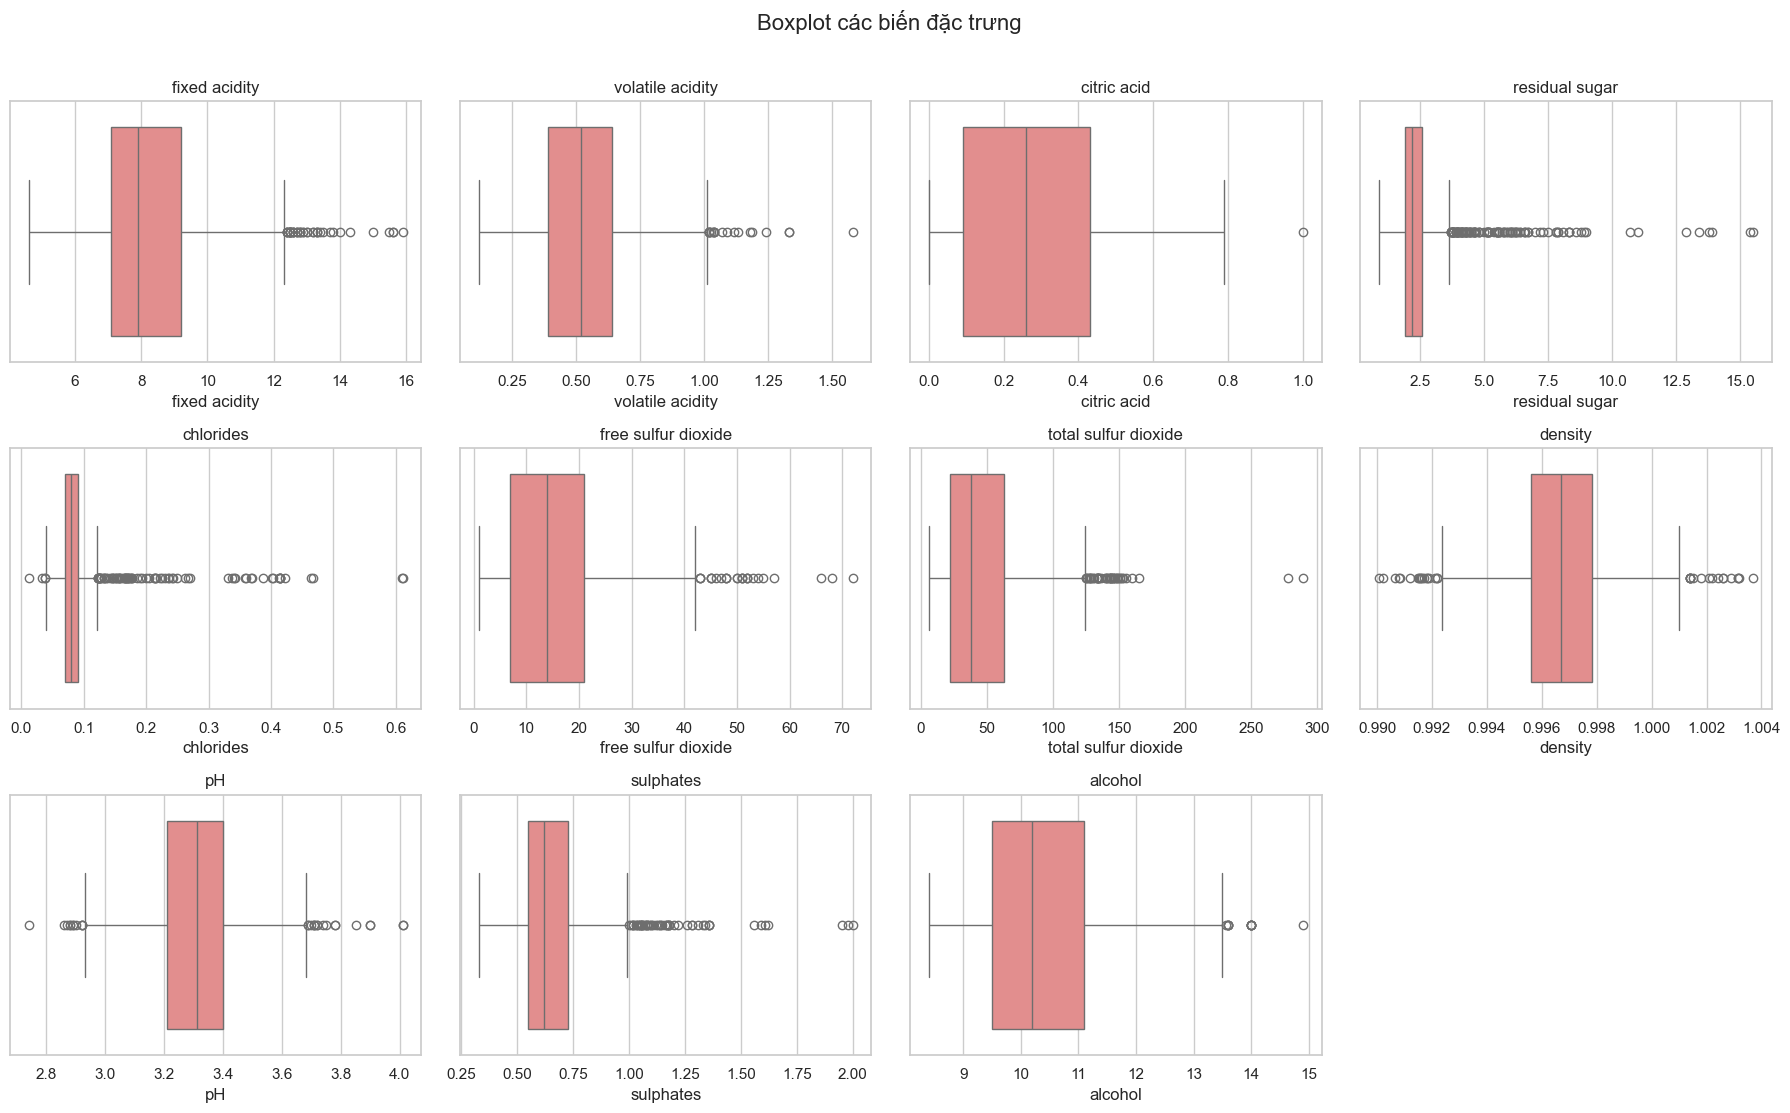

In [15]:
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, c in zip(axes.ravel(), feature_cols):
    sns.boxplot(x=wine_clean[c], ax=ax, color="lightcoral")
    ax.set_title(c)
for ax in axes.ravel()[len(feature_cols):]:
    ax.axis("off")
plt.suptitle("Boxplot các biến đặc trưng", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

## 2.4 Boxplot & Violin plot: biến số theo biến phân loại (`quality`)

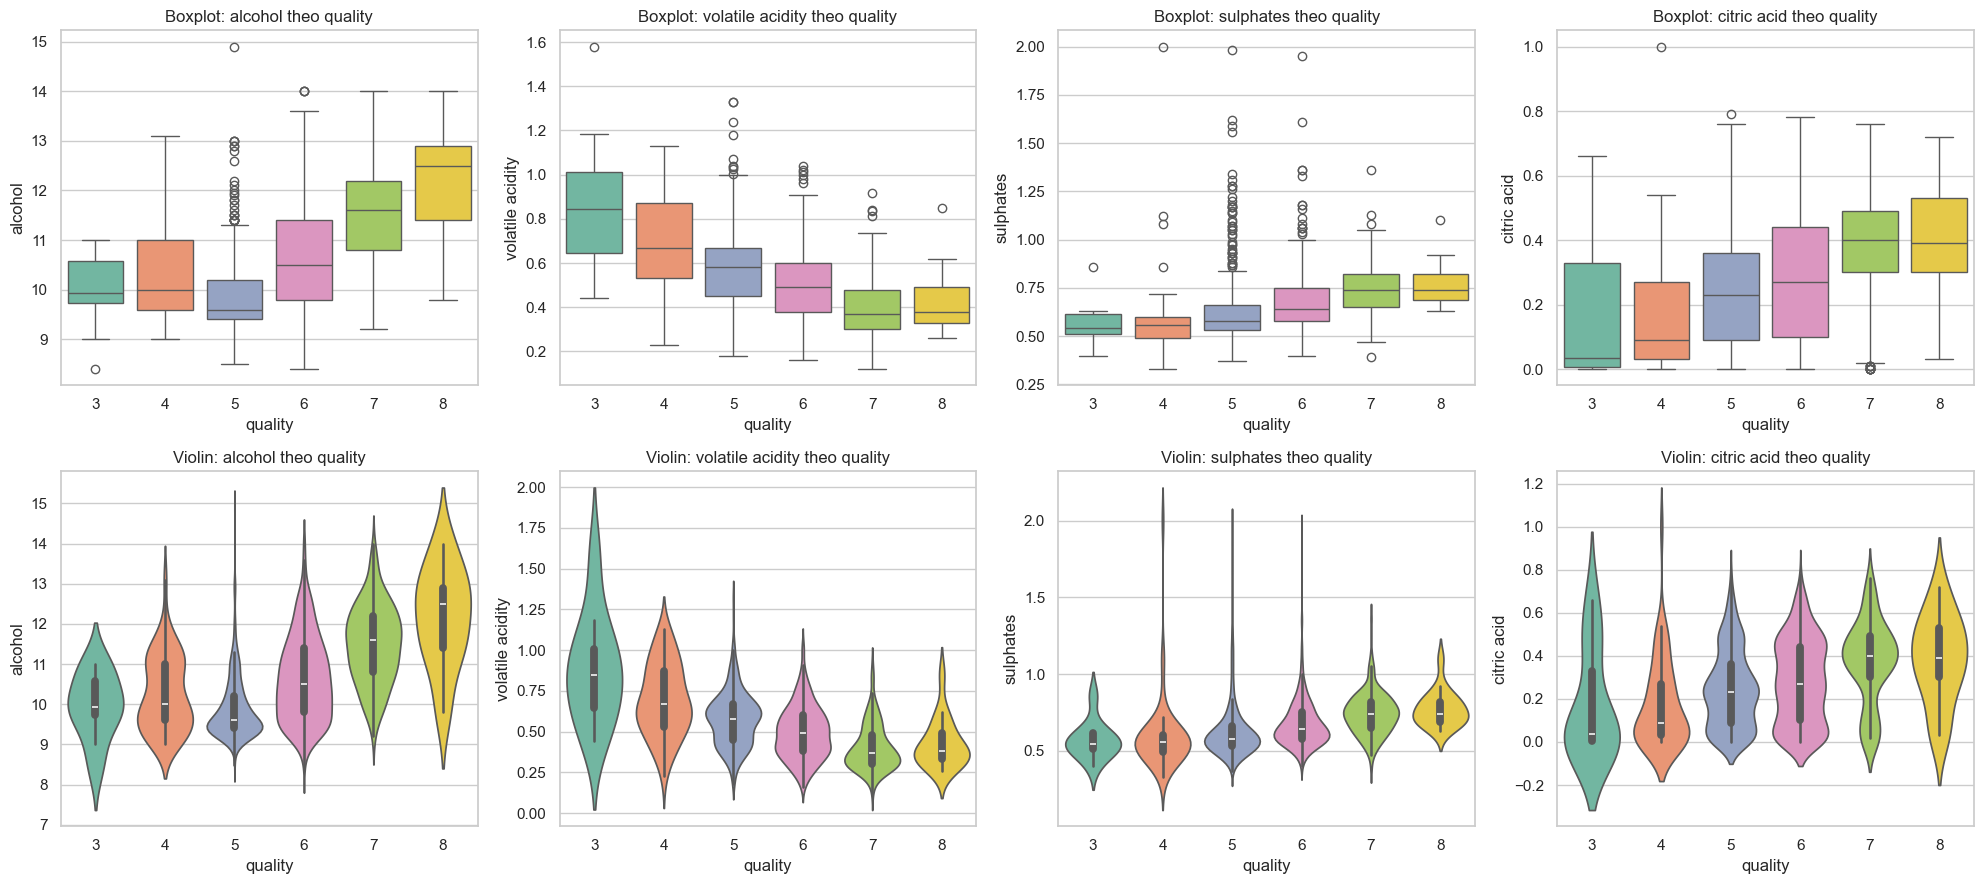

In [16]:
key_feats = ["alcohol", "volatile acidity", "sulphates", "citric acid"]

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for i, c in enumerate(key_feats):
    sns.boxplot(data=wine_clean, x="quality", y=c, ax=axes[0, i], palette="Set2")
    axes[0, i].set_title(f"Boxplot: {c} theo quality")
    sns.violinplot(data=wine_clean, x="quality", y=c, ax=axes[1, i], palette="Set2")
    axes[1, i].set_title(f"Violin: {c} theo quality")
plt.tight_layout()
plt.show()

## 2.5 Bar chart: giá trị trung bình theo nhóm (Matplotlib & Seaborn)
Tương tự bài mẫu "Top 10 areas" – ở đây so sánh giá trị trung bình của `alcohol` và `volatile acidity` theo `quality`.

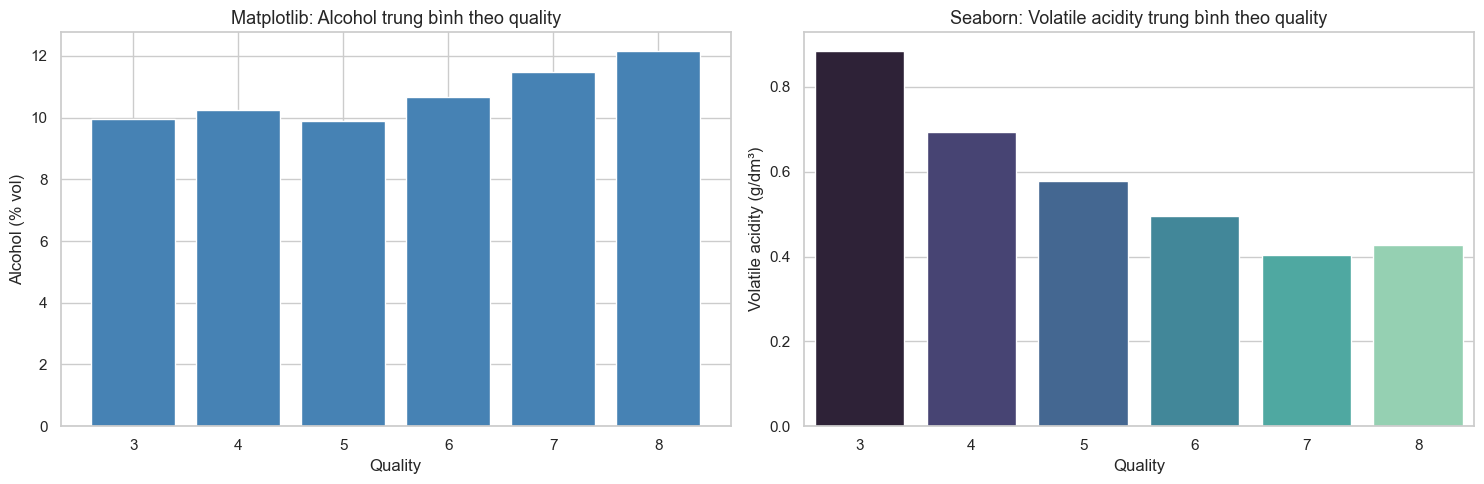

In [17]:
grp = wine_clean.groupby("quality")[["alcohol", "volatile acidity"]].mean().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Matplotlib
axes[0].bar(grp["quality"].astype(str), grp["alcohol"], color="steelblue")
axes[0].set_title("Matplotlib: Alcohol trung bình theo quality", fontsize=13)
axes[0].set_xlabel("Quality"); axes[0].set_ylabel("Alcohol (% vol)")

# Seaborn
sns.barplot(data=grp, x="quality", y="volatile acidity", ax=axes[1], palette="mako")
axes[1].set_title("Seaborn: Volatile acidity trung bình theo quality", fontsize=13)
axes[1].set_xlabel("Quality"); axes[1].set_ylabel("Volatile acidity (g/dm³)")
plt.tight_layout()
plt.show()

## 2.6 Scatter plot – quan hệ hai biến

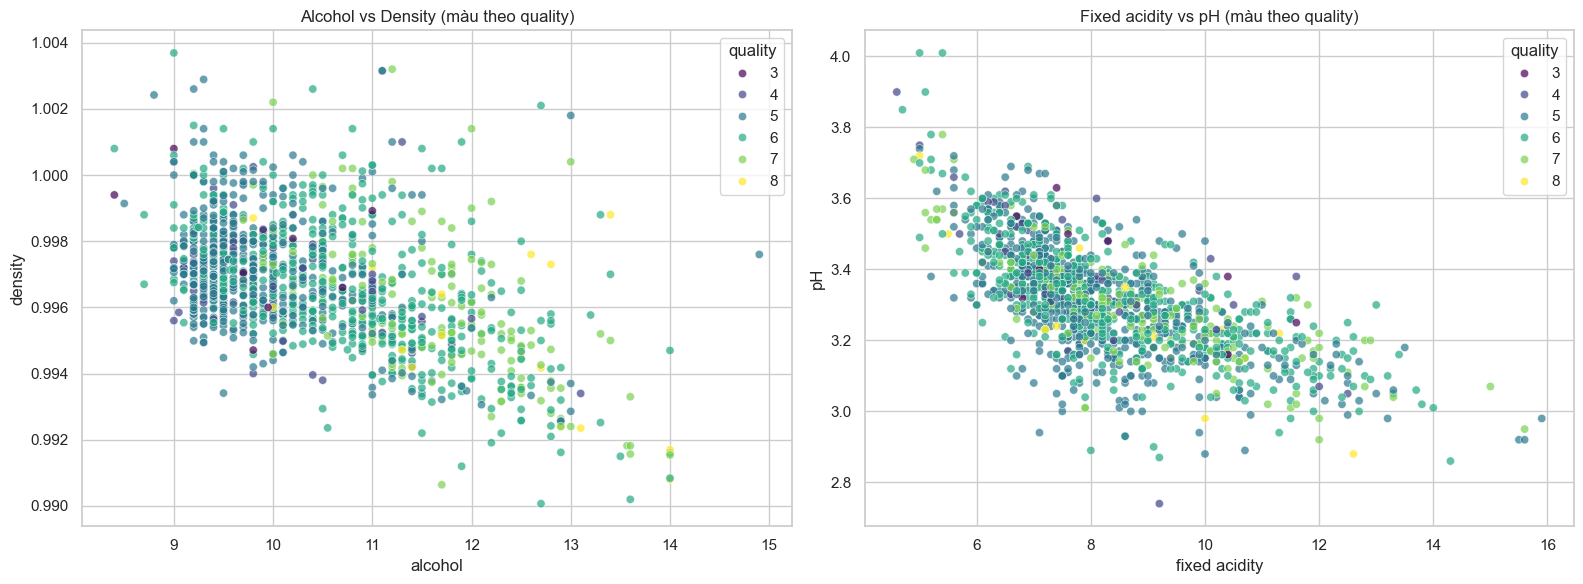

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(data=wine_clean, x="alcohol", y="density", hue="quality",
                palette="viridis", alpha=0.7, ax=axes[0])
axes[0].set_title("Alcohol vs Density (màu theo quality)")

sns.scatterplot(data=wine_clean, x="fixed acidity", y="pH", hue="quality",
                palette="viridis", alpha=0.7, ax=axes[1])
axes[1].set_title("Fixed acidity vs pH (màu theo quality)")
plt.tight_layout()
plt.show()

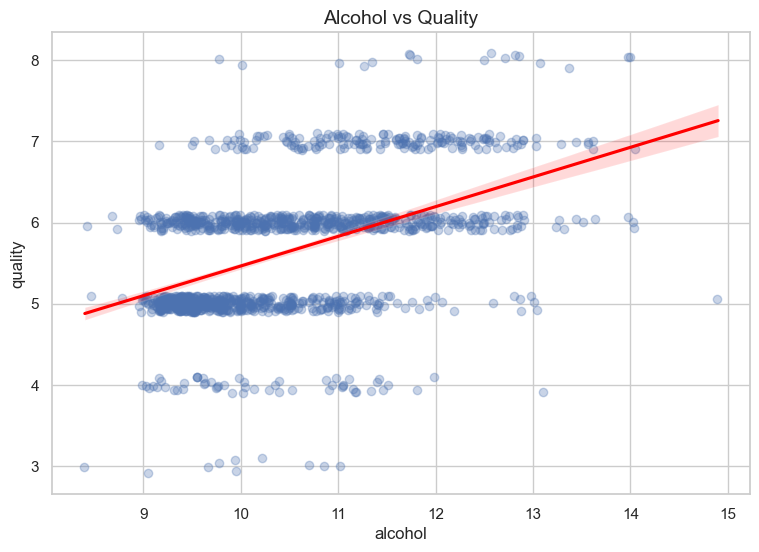

In [19]:
# Scatter + đường hồi quy
plt.figure(figsize=(9, 6))
sns.regplot(data=wine_clean, x="alcohol", y="quality", x_jitter=0.05, y_jitter=0.1,
            scatter_kws={"alpha": 0.3}, line_kws={"color": "red"})
plt.title("Alcohol vs Quality", fontsize=14)
plt.show()

## 2.7 Heatmap ma trận tương quan

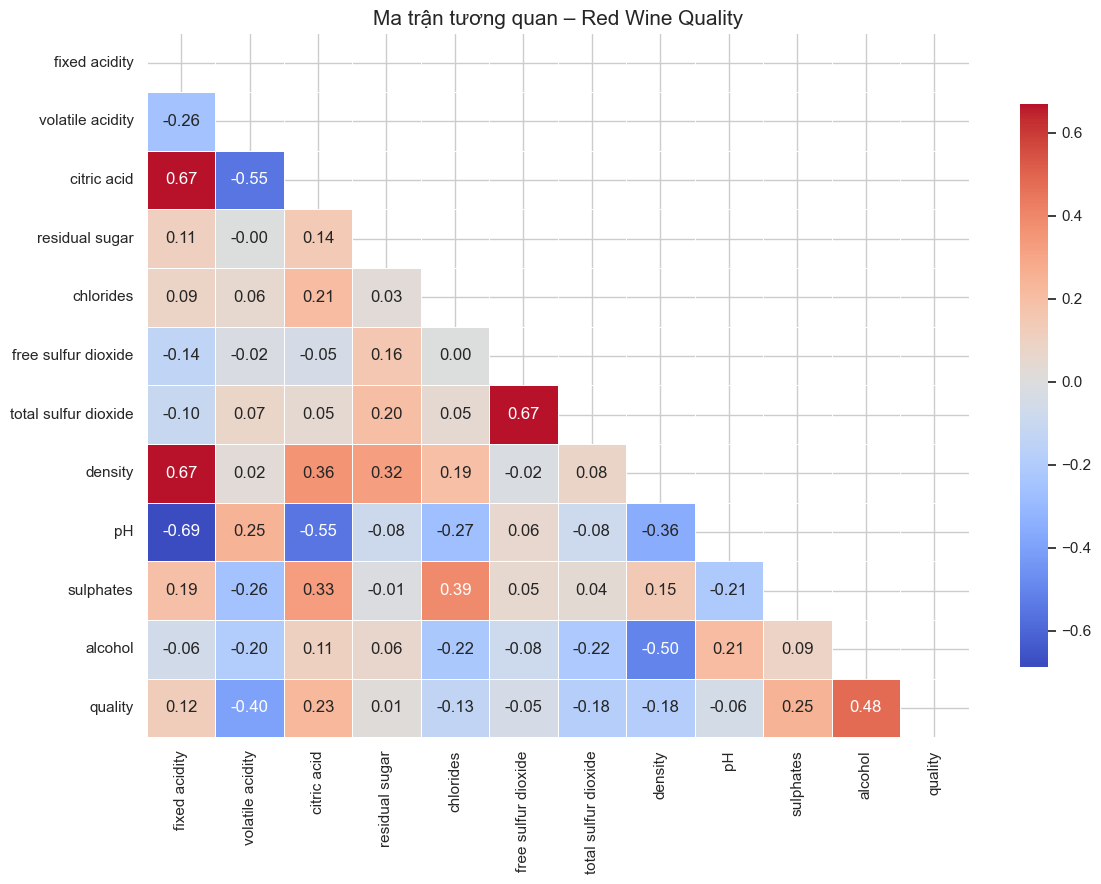

Tương quan của các biến với quality (sắp xếp theo |r|):


alcohol                 0.480
volatile acidity       -0.395
sulphates               0.249
citric acid             0.228
density                -0.184
total sulfur dioxide   -0.178
chlorides              -0.131
fixed acidity           0.119
pH                     -0.055
free sulfur dioxide    -0.050
residual sugar          0.014
Name: quality, dtype: float64

In [20]:
corr = wine_clean.corr(numeric_only=True)

plt.figure(figsize=(12, 9))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Ma trận tương quan – Red Wine Quality", fontsize=15)
plt.tight_layout()
plt.show()

print("Tương quan của các biến với quality (sắp xếp theo |r|):")
corr["quality"].drop("quality").sort_values(key=abs, ascending=False).round(3)

## 2.8 Pairplot các biến quan trọng

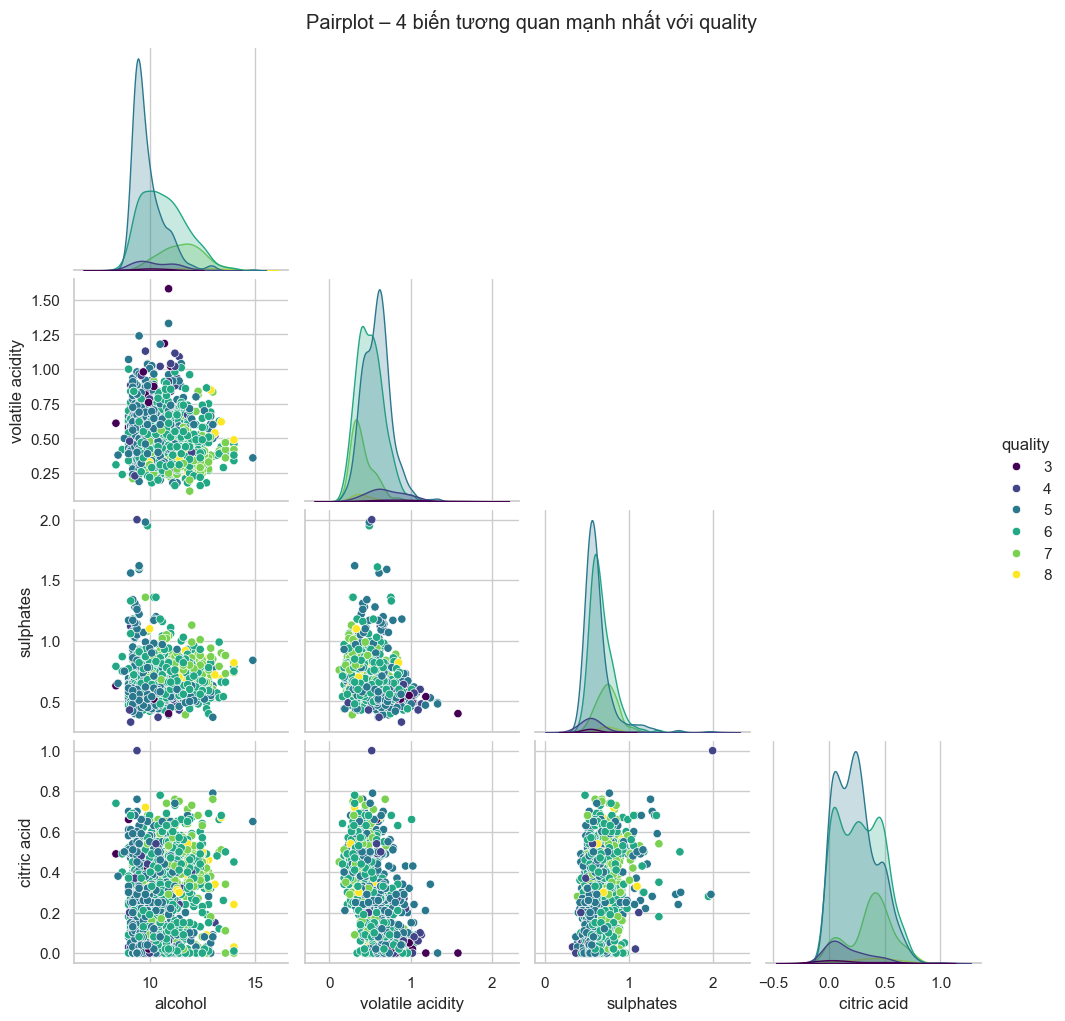

In [21]:
top = corr["quality"].drop("quality").abs().sort_values(ascending=False).head(4).index.tolist()
sns.pairplot(wine_clean[top + ["quality"]], hue="quality", palette="viridis",
             diag_kind="kde", corner=True)
plt.suptitle("Pairplot – 4 biến tương quan mạnh nhất với quality", y=1.02)
plt.show()

## 2.9 Xuất biểu đồ ra file (PNG / PDF)

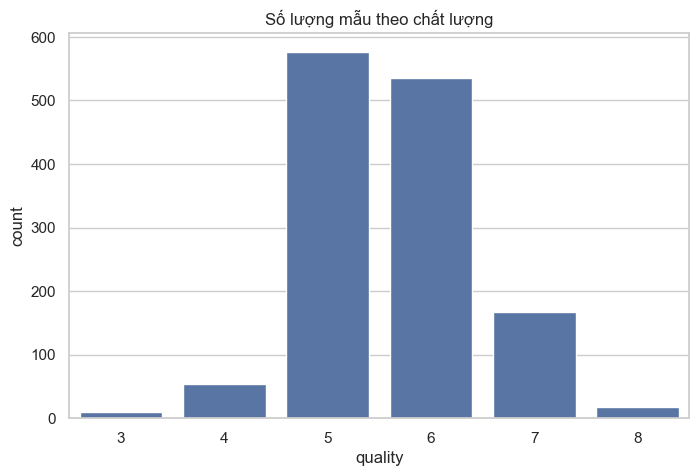

Đã lưu: outputs/wine_quality_count.png và .pdf


In [22]:
os.makedirs("outputs", exist_ok=True)
fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(data=wine_clean, x="quality", ax=ax)
ax.set_title("Số lượng mẫu theo chất lượng")
fig.savefig("outputs/wine_quality_count.png", dpi=300, bbox_inches="tight")
fig.savefig("outputs/wine_quality_count.pdf", bbox_inches="tight")
plt.show()
print("Đã lưu: outputs/wine_quality_count.png và .pdf")


# PHẦN 3. CÔNG CỤ EDA TỰ ĐỘNG – SWEETVIZ (Marketing Campaign)
**SweetViz** tạo báo cáo EDA HTML chỉ bằng vài dòng lệnh, gồm: tổng quan, phân bố từng biến, tương quan, so sánh hai tập dữ liệu, phân tích theo biến mục tiêu.

Cài đặt: `pip install sweetviz`

In [23]:
mk = pd.read_csv(find_file("marketing_campaign.csv"), sep="\t")   # file gốc Kaggle dùng tab
if mk.shape[1] == 1:
    mk = pd.read_csv(find_file("marketing_campaign.csv"), sep=";")
print(mk.shape)
mk.head()

(2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0


In [24]:
# Tiền xử lý nhẹ: đổi kiểu ngày, bỏ cột hằng số, kiểm tra thiếu
mk["Dt_Customer"] = pd.to_datetime(mk["Dt_Customer"], dayfirst=True, errors="coerce")
mk = mk.drop(columns=[c for c in ["Z_CostContact", "Z_Revenue"] if c in mk.columns])
print(mk.isnull().sum()[mk.isnull().sum() > 0])

Income    24
dtype: int64


## 3.1 Báo cáo EDA cơ bản

In [27]:
%pip install -U sweetviz

  Using cached sweetviz-2.3.3-py3-none-any.whl.metadata (22 kB)
  Using cached importlib_resources-7.1.0-py3-none-any.whl.metadata (4.0 kB)
Using cached sweetviz-2.3.3-py3-none-any.whl (15.1 MB)
Using cached importlib_resources-7.1.0-py3-none-any.whl (37 kB)

   ---------------------------------------- 0/2 [importlib_resources]
   -------------------- ------------------- 1/2 [sweetviz]
   -------------------- ------------------- 1/2 [sweetviz]
   ---------------------------------------- 2/2 [sweetviz]

Note: you may need to restart the kernel to use updated packages.


In [28]:
import sweetviz as sv

report = sv.analyze(mk)
os.makedirs("Reports", exist_ok=True)
report.show_html("Reports/sweetviz_marketing.html", open_browser=False)
# Trong Jupyter có thể dùng: report.show_notebook(w="100%", h=800)
print("Đã tạo: Reports/sweetviz_marketing.html")

                                             |          | [  0%]   00:00 -> (? left)

Report Reports/sweetviz_marketing.html was generated.
Đã tạo: Reports/sweetviz_marketing.html


## 3.2 Phân tích theo biến mục tiêu (`Response`)

In [29]:
report_target = sv.analyze(mk, target_feat="Response")
report_target.show_html("Reports/sweetviz_marketing_target.html", open_browser=False)
print("Đã tạo: Reports/sweetviz_marketing_target.html")

                                             |          | [  0%]   00:00 -> (? left)

Report Reports/sweetviz_marketing_target.html was generated.
Đã tạo: Reports/sweetviz_marketing_target.html


## 3.3 So sánh hai nhóm (khách hàng có con vs. không có con)

In [30]:
mk["HasKid"] = (mk["Kidhome"] + mk["Teenhome"]) > 0
g1 = mk[mk["HasKid"]].drop(columns="HasKid")
g2 = mk[~mk["HasKid"]].drop(columns="HasKid")

compare = sv.compare([g1, "Có con"], [g2, "Không có con"])
compare.show_html("Reports/sweetviz_compare.html", open_browser=False)
print("Đã tạo: Reports/sweetviz_compare.html")

                                             |          | [  0%]   00:00 -> (? left)

Report Reports/sweetviz_compare.html was generated.
Đã tạo: Reports/sweetviz_compare.html
